# Phase 2 — Building customer states from RFM (RQ1)

**Proposal sections:** 3.4 RFM-based customer segmentation · 3.6 Leakage control

**Input:** `data/processed/customer_snapshot_panel.parquet` (from notebook 01)
**Outputs:**
- `models/state_model.joblib` — frozen transformation + scaler + K-Means centroids (fitted on S1–S5 only)
- `data/processed/panel_with_states.parquet` / `.csv` — panel + `Segment` (0..k-1) + `SegmentName`
- `outputs/tables/phase2_*.csv`, `outputs/figures/phase2_*.png`

**Rules followed**
1. States are defined by **R, F, M** only; the other behavioural features are used for prediction / description.
2. Any variable with |skew| > 1 on the training rows is `log1p`-transformed and then standardised.
3. The scaler and centroids are fitted on the **training snapshots S1–S5** (all customer × snapshot rows pooled) and then frozen. S6–S8 are only *assigned* to the nearest centroid.
4. k is chosen with the **Elbow** method (inertia curve against k), supported by two numeric rules so that the elbow does not depend on judgement by eye (Kneedle, second difference), and cross-checked with Silhouette, Prediction Strength, cluster size and stability across several training windows / seeds. States are named only after their profiles have been inspected.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

from config import (PROCESSED, FIGURES, TABLES, ROOT, RANDOM_STATE, SNAPSHOT_ORDER, TRAIN_ORIGINS, TEST_ORIGINS,
                    CLUSTER_FEATURES, SKEW_THRESHOLD, K_CANDIDATES, N_STATES, STATE_NAMES, STATE_COLORS)
from states import fit_state_model

MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a92", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5c5c57",
                     "ytick.color": "#5c5c57", "font.size": 10, "lines.linewidth": 2})

panel = pd.read_parquet(PROCESSED / "customer_snapshot_panel.parquet")
train = panel[panel["snapshot"].isin(TRAIN_ORIGINS)].copy()
print(f"Panel rows: {len(panel):,} | training rows (S1–S5): {len(train):,}")

Panel rows: 33,842 | training rows (S1–S5): 17,592


## 1. Clustering inputs and transformation

In [2]:
skew = pd.DataFrame({"skew (raw)": train[CLUSTER_FEATURES].skew(),
                     "skew (log1p)": np.log1p(train[CLUSTER_FEATURES]).skew()})
skew["log1p applied"] = skew["skew (raw)"].abs() > SKEW_THRESHOLD
skew

,skew (raw),skew (log1p),log1p applied
Recency,1.426,-0.845,True
Frequency,10.416,1.335,True
Monetary,25.356,0.293,True


All three variables exceed the |skew| > 1 threshold on the training rows (Recency 1.4; Frequency 10.4; Monetary 25.4), so all three are `log1p`-transformed before standardisation.

## 2. Choosing k with the Elbow method

The **Elbow** method plots *inertia* (the sum of squared distances from each customer to its centroid) against k. Adding clusters always lowers inertia; k is chosen at the "elbow" — the point after which an extra cluster reduces inertia only a little. Because reading a plot is subjective, the procedure below was fixed before looking at the results and adds numeric rules as checks:

| # | Criterion | Role | Decision rule |
|---|---|---|---|
| 1 | **Elbow** — inertia curve against k | **primary** | elbow of the curve, located numerically with **Kneedle** (the point furthest from the chord joining k = 2 and k = 10 after rescaling) and the largest **second difference**; table of % inertia reduction at each step |
| 2 | **Silhouette, Davies-Bouldin, Calinski-Harabasz** | cross-check | report the best k among k ≥ 3 (k = 2 always wins because it is the coarsest split); not used to overturn the Elbow decision |
| 3 | **Prediction Strength** (Tibshirani & Walther, 2005) | reproducibility condition | the chosen k must have PS ≥ 0.80 |
| 4 | **Cluster size** | learnability condition | every state ≥ 5 % of the training rows (Macro-F1 weights all classes equally, so a very small class makes results noisy) |
| 5 | **Stability** | the choice itself must be stable | repeated on 3 sliding training windows (S1–S3, S2–S4, S3–S5) and 3 seeds on S1–S5; final k = majority choice |

Prediction Strength uses 20 random half-splits; bootstrap stability (ARI) uses 10 resamples.

Results for each (window, index, seed) are cached in `outputs/tables/k_selection_raw/`. Set `RECOMPUTE = True` to recompute everything.

In [3]:
from k_selection import evaluate, decide, elbow_table, PS_THRESHOLD, MIN_STATE_SHARE
RECOMPUTE = False
RAW = TABLES / "k_selection_raw"

def run_window(snaps, seed, metrics=("internal", "ps")):
    m = fit_state_model(panel, snaps, k=2)                  # only used to get the transformation for this data window
    Zw = m.transform(panel[panel["snapshot"].isin(snaps)])
    parts = [evaluate(Zw, "-".join(snaps), met, seed, RAW, recompute=RECOMPUTE).set_index("k")
             .drop(columns=["window", "seed", "metric_group", "n"]) for met in metrics]
    return pd.concat(parts, axis=1)

k_table = run_window(TRAIN_ORIGINS, RANDOM_STATE, metrics=("internal", "ps", "boot"))
k_table = k_table.join(elbow_table(k_table["inertia"]).drop(columns="inertia"))
k_table[["inertia", "drop_pct", "second_diff", "prediction_strength", "ps_sd", "stability_ARI", "stability_ARI_sd",
         "silhouette", "davies_bouldin", "calinski_harabasz", "smallest_state_share"]]

,inertia,drop_pct,second_diff,prediction_strength,ps_sd,stability_ARI,stability_ARI_sd,silhouette,davies_bouldin,calinski_harabasz,smallest_state_share
k,,,,,,,,,,,
2,"28,754.744",NaN,NaN,0.972,0.015,0.987,0.008,0.418,0.957,"14,694.543",0.354
3,"22,476.365",21.834,"1,155.559",0.859,0.121,0.900,0.146,0.318,1.136,"11,855.866",0.164
4,"17,353.545",22.792,"2,791.365",0.873,0.059,0.956,0.022,0.341,0.975,"11,967.097",0.141
5,"15,022.091",13.435,350.632,0.779,0.149,0.935,0.023,0.301,1.043,"11,050.122",0.067
6,"13,041.268",13.186,785.120,0.775,0.073,0.923,0.028,0.301,0.979,"10,716.472",0.055
7,"11,845.567",9.169,127.833,0.630,0.182,0.691,0.215,0.269,1.040,"10,127.256",0.042
8,"10,777.698",9.015,82.856,0.486,0.113,0.793,0.165,0.274,1.057,"9,788.772",0.037
9,"9,792.686",9.139,279.774,0.638,0.065,0.841,0.084,0.278,0.999,"9,647.251",0.030
10,"9,087.447",7.202,NaN,0.748,0.085,0.868,0.126,0.271,1.003,"9,391.949",0.026


In [4]:
decision_main = decide(k_table)
K_SELECTED = decision_main["k_elbow_kneedle"]
decision_main

{'k_elbow_kneedle': 4,
 'k_elbow_2nd_diff': 4,
 'k_largest_PS>=0.8': 4,
 'elbow_k_is_replicable': True,
 'elbow_k_min_share_ok': True}

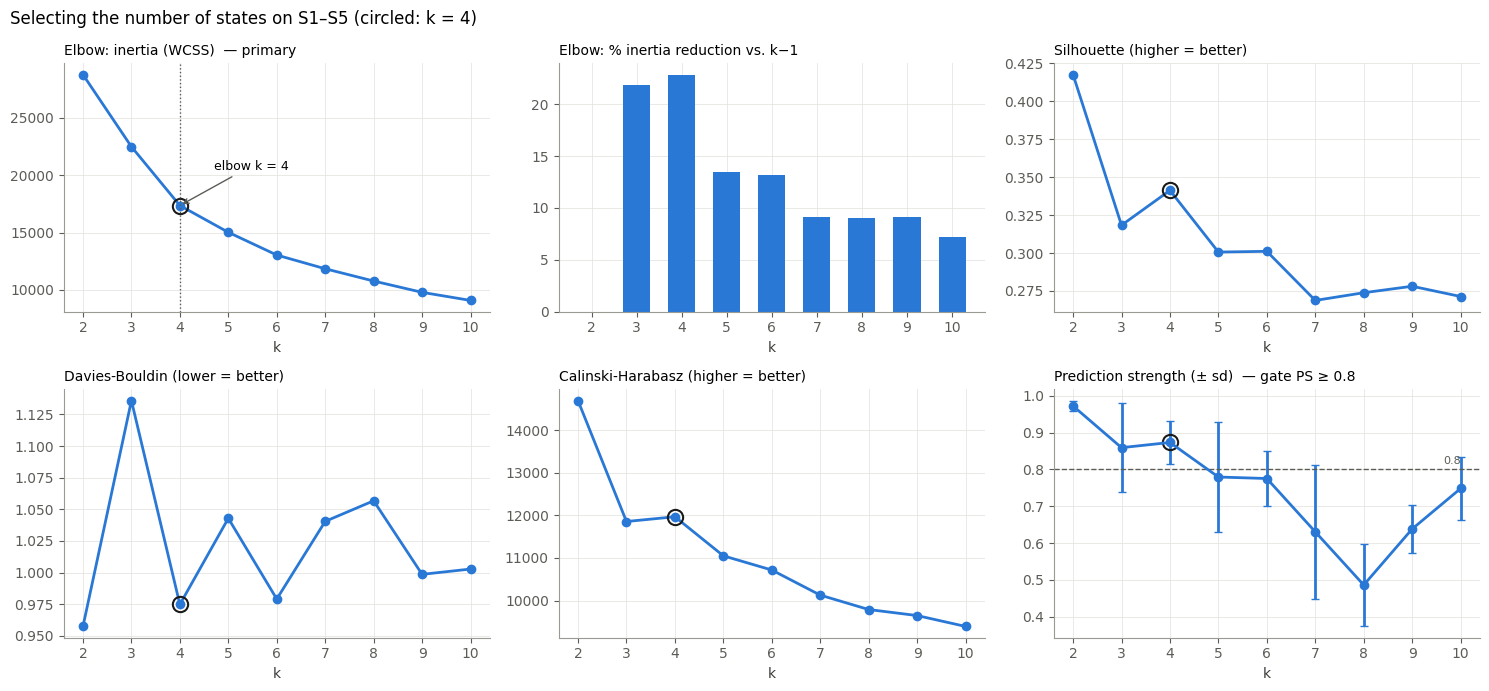

In [5]:
ks = k_table.index.values
blue, grey = "#2a78d6", "#5c5c57"
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
panels = [("inertia", None, "Elbow: inertia (WCSS)  — primary"),
          ("drop_pct", None, "Elbow: % inertia reduction vs. k−1"),
          ("silhouette", None, "Silhouette (higher = better)"),
          ("davies_bouldin", None, "Davies-Bouldin (lower = better)"),
          ("calinski_harabasz", None, "Calinski-Harabasz (higher = better)"),
          ("prediction_strength", "ps_sd", "Prediction strength (± sd)  — gate PS ≥ 0.8")]
for ax, (col, err, title) in zip(axes.ravel(), panels):
    y = k_table[col].values
    if err:
        ax.errorbar(ks, y, yerr=k_table[err].values, color=blue, marker="o", markersize=6, capsize=3, linewidth=2)
    elif col == "drop_pct":
        ax.bar(ks, np.nan_to_num(y), color=blue, width=0.6)
    else:
        ax.plot(ks, y, color=blue, marker="o", markersize=6)
    if col != "drop_pct":
        ax.plot([K_SELECTED], [k_table.loc[K_SELECTED, col]], marker="o", markersize=11, markerfacecolor="none",
                markeredgecolor="#1a1a19", markeredgewidth=1.5)
    if col == "inertia":
        ax.axvline(K_SELECTED, color=grey, linestyle=":", linewidth=1)
        ax.annotate(f"elbow k = {K_SELECTED}", (K_SELECTED, k_table.loc[K_SELECTED, col]),
                    xytext=(K_SELECTED + 0.7, k_table.loc[K_SELECTED, col] * 1.18), fontsize=9,
                    arrowprops=dict(arrowstyle="->", color=grey))
    if col == "prediction_strength":
        ax.axhline(PS_THRESHOLD, color=grey, linestyle="--", linewidth=1)
        ax.text(ks[-1], PS_THRESHOLD + 0.01, "0.8", ha="right", va="bottom", fontsize=8, color=grey)
    ax.set_title(title, loc="left", fontsize=10); ax.set_xticks(ks); ax.set_xlabel("k")
fig.suptitle(f"Selecting the number of states on S1–S5 (circled: k = {K_SELECTED})", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIGURES / "phase2_k_selection.png", dpi=150, bbox_inches="tight")

### Stability of the choice across training windows and seeds

In [6]:
runs = [(TRAIN_ORIGINS, RANDOM_STATE), (TRAIN_ORIGINS, 7), (TRAIN_ORIGINS, 2024),
        (["S1", "S2", "S3"], RANDOM_STATE), (["S2", "S3", "S4"], RANDOM_STATE), (["S3", "S4", "S5"], RANDOM_STATE)]
rob = []
for snaps, seed in runs:
    t = run_window(snaps, seed)
    d = decide(t)
    t3 = t[t.index >= 3]
    rob.append({"window": "–".join([snaps[0], snaps[-1]]), "seed": seed, "rows": int(len(panel[panel.snapshot.isin(snaps)])),
                **d, "best Silhouette (k≥3)": t3["silhouette"].idxmax(),
                "best DBI (k≥3)": t3["davies_bouldin"].idxmin(), "best CH (k≥3)": t3["calinski_harabasz"].idxmax()})
robustness = pd.DataFrame(rob)
robustness

,window,seed,rows,k_elbow_kneedle,k_elbow_2nd_diff,k_largest_PS>=0.8,elbow_k_is_replicable,elbow_k_min_share_ok,best Silhouette (k≥3),best DBI (k≥3),best CH (k≥3)
0,S1–S5,42,17592,4,4,4,True,True,4,4,4
1,S1–S5,7,17592,4,4,4,True,True,4,4,4
2,S1–S5,2024,17592,4,4,4,True,True,4,4,4
3,S1–S3,42,8609,4,4,4,True,True,4,4,4
4,S2–S4,42,10780,5,4,4,False,True,4,4,3
5,S3–S5,42,12514,5,4,5,True,True,4,6,3


In [7]:
votes = robustness["k_elbow_kneedle"].value_counts()
votes_sd = robustness["k_elbow_2nd_diff"].value_counts()
K_FINAL = int(votes.idxmax())
gates_ok = robustness.loc[robustness.k_elbow_kneedle == K_FINAL, ["elbow_k_is_replicable", "elbow_k_min_share_ok"]].all().all()
print(f"Elbow (Kneedle) votes: {votes.to_dict()}  ->  k = {K_FINAL}  (all gates passed: {gates_ok})")
print(f"Elbow (2nd difference) votes: {votes_sd.to_dict()}")
print(f"Largest k with PS >= 0.8: {robustness['k_largest_PS>=0.8'].value_counts().to_dict()}")
assert K_FINAL == N_STATES, f"config.N_STATES ({N_STATES}) differs from the selected k ({K_FINAL}) — update src/config.py"

Elbow (Kneedle) votes: {4: 4, 5: 2}  ->  k = 4  (all gates passed: True)
Elbow (2nd difference) votes: {4: 6}
Largest k with PS >= 0.8: {4: 5, 5: 1}


**Result: k = 4, chosen with the Elbow method and supported by the other criteria.**

- **Elbow on S1–S5:** inertia falls 28,755 → 22,476 → **17,354** (k = 2 → 3 → 4), about 22 % at each step. From k = 4 → 5 the reduction is only 13.4 %, and then about 9 % at k = 7–9: the curve bends right after k = 4, so a fifth cluster onwards adds little. Both numeric rules point to k = 4: Kneedle selects k = 4 and the second difference is largest at k = 4 (2,791, more than twice the next largest value, 1,156 at k = 3).
- **Stability of the elbow (6 runs: 3 seeds × S1–S5, and 3 sliding windows):** the second difference selects k = 4 in 6/6 runs. Kneedle selects k = 4 in 4/6 runs; on the two shorter windows (S2–S4, S3–S5) it selects k = 5 because the inertia curve bends more gradually there. At k = 5 on S2–S4, Prediction Strength does not reach the 0.8 threshold and the smallest state covers only 5.5–6.7 % (close to the 5 % threshold), so k = 4 remains the majority and safer choice.
- **Prediction Strength:** k = 4 is reproducible in every run (PS 0.87 on S1–S5) and is the *largest* reproducible k in 5/6 runs. For k ≥ 7, PS falls to 0.49–0.64: these finer splits are not reproducible.
- **Cluster size:** the smallest state at k = 4 holds 14 % of the training rows (threshold: 5 %).
- **Cross-check indices** (among k ≥ 3): Silhouette is best at k = 4 in 6/6 runs, Davies-Bouldin in 5/6 and Calinski-Harabasz in 4/6 (k = 3 on the other two windows). Bootstrap ARI at k = 4 is 0.956 ± 0.022, against 0.90 ± 0.15 at k = 3.

**Why not k = 2?** Silhouette, DBI and CH are best at k = 2 because the strongest split in RFM data is "still buying / stopped buying", and these indices are known to favour the coarsest split. On the Elbow curve, k = 2 is not yet the elbow: inertia still falls sharply (about 22 % per step) when a third and a fourth cluster are added.
**Why not k = 5–6 or more?** The reduction in inertia has already slowed (≤ 13.4 % per step), PS drops below 0.8 (0.78 at k = 5–6 on S1–S5), and the smallest state shrinks to 5.5–6.7 % (k = 5–6) and then 2.6–4.2 % (k ≥ 7).

**Methodological note:** the Elbow method is inherently visual. Cross-checking with Kneedle, the second difference, PS and consistency across windows makes the k = 4 conclusion verifiable, but the report should state that on the two short windows Kneedle leans towards k = 5.

## 3. Fitting and freezing the state model on S1–S5

In [8]:
state_model = fit_state_model(panel, TRAIN_ORIGINS, k=N_STATES)
joblib.dump(state_model, MODELS / "state_model.joblib")
print("log1p columns:", state_model.log_cols, "| fitted on:", state_model.fitted_on)

# centroids back in original units (inverse of standardisation and log1p)
centers_orig = pd.DataFrame(state_model.scaler.inverse_transform(state_model.centers_z.values),
                            columns=CLUSTER_FEATURES, index=state_model.centers_z.index)
for c in state_model.log_cols:
    centers_orig[c] = np.expm1(centers_orig[c])
pd.concat({"centroid (z-score)": state_model.centers_z, "centroid (original units)": centers_orig}, axis=1)

log1p columns: ['Recency', 'Frequency', 'Monetary'] | fitted on: ['S1', 'S2', 'S3', 'S4', 'S5']


centroid (z-score)                    centroid (original units)  \
                 Recency Frequency Monetary                   Recency   
state                                                                   
0                  0.677    -0.756   -0.815                   132.078   
1                  0.262     0.317    0.483                    77.252   
2                 -1.277    -0.286   -0.186                     9.912   
3                 -1.010     1.815    1.520                    14.361   

                           
      Frequency  Monetary  
state                      
0         1.203   232.926  
1         3.501 1,203.568  
2         2.013   516.794  
3        11.211 4,461.952

In [9]:
panel["Segment"] = state_model.predict(panel)
panel["SegmentName"] = panel["Segment"].map(STATE_NAMES)
train = panel[panel["snapshot"].isin(TRAIN_ORIGINS)]

profile_cols = ["Recency", "Frequency", "Monetary", "AOV", "ProductVariety", "Tenure", "RecentOrders", "RecentSpend"]
profiles = train.groupby("Segment")[profile_cols].median()
profiles.insert(0, "share of training rows", train["Segment"].value_counts(normalize=True).sort_index())
profiles.insert(0, "name", profiles.index.map(STATE_NAMES))
profiles["% active last 90d"] = train.groupby("Segment")["RecentOrders"].apply(lambda s: (s > 0).mean())
profiles

,name,share of training rows,Recency,Frequency,Monetary,AOV,ProductVariety,Tenure,RecentOrders,RecentSpend,% active last 90d
Segment,,,,,,,,,,,
0,Dormant Low-Value,0.401,138.000,1.000,259.170,206.700,17.000,158.000,0.000,0.000,0.283
1,Lapsing Mid-Value,0.296,77.000,3.000,"1,161.895",331.528,55.000,261.000,1.000,179.775,0.570
2,Recent Low-Frequency,0.162,13.000,2.000,538.700,275.075,31.000,63.000,1.000,359.690,1.000
3,Active High-Value,0.141,17.000,10.000,"3,855.835",374.558,121.000,304.000,3.000,"1,056.970",0.971


In [10]:
# The names in config.py must match the inspected profiles; fail loudly if a re-run reorders them.
p = profiles
assert p["Recency"].idxmax() == 0, "state 0 should be the least recent (dormant)"
assert p["Frequency"].idxmax() == 3 and p["Monetary"].idxmax() == 3, "state 3 should be the high-value state"
assert p["Recency"].idxmin() == 2 and p["Tenure"].idxmin() == 2, "state 2 should be recent with short tenure"
print("State names consistent with profiles ✓")

State names consistent with profiles ✓


**Interpreting the states (training data, median values)**

| id | name | description |
|---|---|---|
| 0 | **Dormant Low-Value** | median ~4.5 months since the last purchase, 1 order, low spend; only ~28 % bought in the last 90 days |
| 1 | **Lapsing Mid-Value** | established customers (~9 months' tenure, ~3 orders, ~£1.2k) whose last order was ~2.5 months ago |
| 2 | **Recent Low-Frequency** | bought within the last ~2 weeks but only ~2 orders and a short tenure — mostly new or returning customers |
| 3 | **Active High-Value** | recent buyers with ~10 orders and ~£3.9k cumulative spend; the loyal core of the customer base |

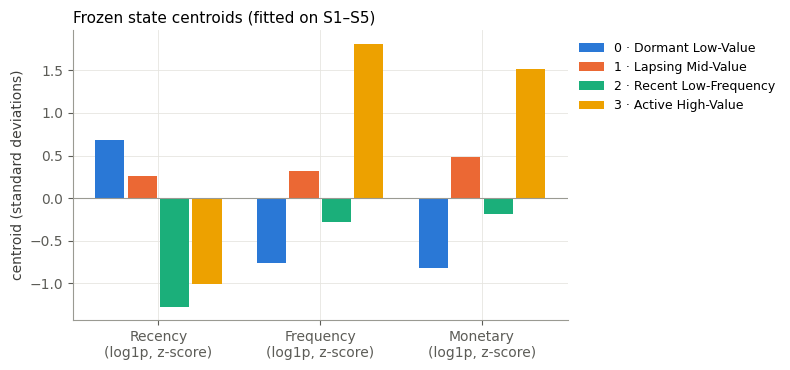

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.2
x = np.arange(len(CLUSTER_FEATURES))
for i, s in enumerate(state_model.centers_z.index):
    ax.bar(x + (i - 1.5) * w, state_model.centers_z.loc[s], width=w - 0.02, color=STATE_COLORS[s],
           label=f"{s} · {STATE_NAMES[s]}")
ax.axhline(0, color="#9a9a92", linewidth=0.8)
ax.set_xticks(x, [f"{c}\n(log1p, z-score)" for c in CLUSTER_FEATURES])
ax.set_ylabel("centroid (standard deviations)")
ax.set_title("Frozen state centroids (fitted on S1–S5)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); fig.savefig(FIGURES / "phase2_state_centroids.png", dpi=150, bbox_inches="tight")

## 4. State distribution across snapshots (assigned with the frozen model)

In [12]:
dist_counts = pd.crosstab(panel["snapshot"], panel["Segment"]).reindex(SNAPSHOT_ORDER)
dist_share = dist_counts.div(dist_counts.sum(axis=1), axis=0)
dist_counts.columns = dist_share.columns = [f"{s} {STATE_NAMES[s]}" for s in dist_counts.columns]
pd.concat({"customers": dist_counts, "share": dist_share}, axis=1)

customers                                             \
         0 Dormant Low-Value 1 Lapsing Mid-Value 2 Recent Low-Frequency   
snapshot                                                                  
S1                       813                 319                    851   
S2                      1221                 755                    654   
S3                      1420                 954                    631   
S4                      1701                1586                    309   
S5                      1898                1592                    410   
S6                      2040                1694                    358   
S7                      2110                1732                    484   
S8                      2080                1826                    609   

                                           share                      \
         3 Active High-Value 0 Dormant Low-Value 1 Lapsing Mid-Value   
snapshot                                                               
S1                       149               0.381               0.150   
S2                       316               0.414               0.256   
S3                       526               0.402               0.270   
S4                       707               0.395               0.369   
S5                       780               0.406               0.340   
S6                       915               0.407               0.338   
S7                      1078               0.390               0.321   
S8                      1324               0.356               0.313   

                                                     
         2 Recent Low-Frequency 3 Active High-Value  
snapshot                                             
S1                        0.399               0.070  
S2                        0.222               0.107  
S3                        0.179               0.149  
S4                        0.072               0.164  
S5                        0.088               0.167  
S6                        0.071               0.183  
S7                        0.090               0.199  
S8                        0.104               0.227

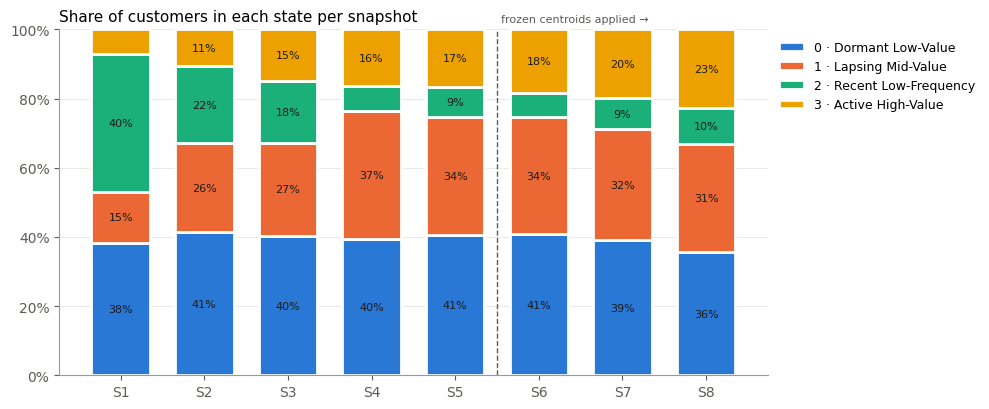

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(SNAPSHOT_ORDER))
shares = dist_share.values
for j, s in enumerate(range(N_STATES)):
    ax.bar(SNAPSHOT_ORDER, shares[:, j], bottom=bottom, color=STATE_COLORS[s], edgecolor="white",
           linewidth=2, width=0.7, label=f"{s} · {STATE_NAMES[s]}")
    for i, v in enumerate(shares[:, j]):
        if v >= 0.08:
            ax.text(i, bottom[i] + v / 2, f"{v:.0%}", ha="center", va="center", fontsize=8, color="#1a1a19")
    bottom += shares[:, j]
ax.axvline(4.5, color="#5c5c57", linestyle="--", linewidth=1)
ax.text(4.55, 1.02, "frozen centroids applied →", fontsize=8, color="#5c5c57", transform=ax.get_xaxis_transform())
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Share of customers in each state per snapshot", loc="left", fontsize=11); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); fig.savefig(FIGURES / "phase2_state_share_by_snapshot.png", dpi=150, bbox_inches="tight")

Reading the distribution: S1 is dominated by *Recent Low-Frequency* because in the first quarter of the data every customer is new. The *Active High-Value* share rises steadily, partly because cumulative Frequency and Monetary grow mechanically over time (proposal Section 3.8) — so interpretation in later phases should rely more on Recency and the recent-activity features.

## 5. Do the frozen states still fit later snapshots?

Two checks per snapshot, including S6–S8 (data the model has not seen):
- **Silhouette** of the frozen assignment on that snapshot (it should not drop sharply after S5).
- **Agreement with a refit**: run K-Means with the same k on that snapshot *only* and compute the ARI against the frozen assignment. A high ARI means the frozen states are close to how the data would split on their own, i.e. little drift.

These are diagnostics only — nothing here feeds back into the frozen model.

In [14]:
drift = []
for s in SNAPSHOT_ORDER:
    rows_s = panel[panel["snapshot"] == s]
    Zs = state_model.transform(rows_s)
    frozen = rows_s["Segment"].values
    refit = KMeans(n_clusters=N_STATES, n_init=20, random_state=RANDOM_STATE).fit_predict(Zs)
    drift.append({"snapshot": s, "split": "train" if s in TRAIN_ORIGINS else "out-of-sample",
                  "rows": len(rows_s),
                  "silhouette (frozen)": silhouette_score(Zs, frozen, sample_size=min(4000, len(Zs)), random_state=0),
                  "ARI frozen vs refit": adjusted_rand_score(frozen, refit),
                  "mean dist. to own centroid": state_model.distances(rows_s)[np.arange(len(rows_s)), frozen].mean()})
drift = pd.DataFrame(drift).set_index("snapshot")
drift

,split,rows,silhouette (frozen),ARI frozen vs refit,mean dist. to own centroid
snapshot,,,,,
S1,train,2132,0.285,0.520,0.916
S2,train,2946,0.332,0.773,0.865
S3,train,3531,0.362,0.903,0.869
S4,train,4303,0.301,0.515,0.844
S5,train,4680,0.377,0.900,0.929
S6,out-of-sample,5007,0.365,0.773,1.001
S7,out-of-sample,5404,0.377,0.813,1.079
S8,out-of-sample,5839,0.338,0.660,1.099


**Reading the drift checks.** Silhouette on the out-of-sample snapshots S6–S8 (0.34–0.38) is as good as on the training snapshots, so the frozen states still separate later data well. Agreement with a per-snapshot refit is moderate to high (ARI 0.66–0.81 out of sample); the lower values at S1 and S4 reflect the unusual customer mix of those quarters (S1 consists only of new customers, S4 is the Christmas peak) rather than a failure of the frozen model. The mean distance to the customer's own centroid rises slowly after S5 (≈ 0.9 → 1.1 standard deviations), consistent with cumulative Frequency/Monetary growing mechanically — a mild drift to mention under limitations, and the reason the proposal recommends monitoring transition drift in deployment (Section 4.2).

## 6. Saving the results

In [15]:
panel.to_parquet(PROCESSED / "panel_with_states.parquet", index=False)
panel.to_csv(PROCESSED / "panel_with_states.csv", index=False)
k_table.to_csv(TABLES / "phase2_k_selection.csv")
robustness.to_csv(TABLES / "phase2_k_selection_robustness.csv", index=False)
profiles.to_csv(TABLES / "phase2_state_profiles.csv")
pd.concat({"customers": dist_counts, "share": dist_share}, axis=1).to_csv(TABLES / "phase2_state_distribution.csv")
drift.to_csv(TABLES / "phase2_state_drift_check.csv")
pd.concat({"z": state_model.centers_z, "original": centers_orig}, axis=1).to_csv(TABLES / "phase2_centroids.csv")
print("saved", len(panel), "rows with states")

saved 33842 rows with states


## Summary & hand-off to Phase 3

- **Answer to RQ1 (descriptive):** four RFM-based customer states — Dormant Low-Value, Lapsing Mid-Value, Recent Low-Frequency, Active High-Value — chosen with the Elbow method and supported by the reproducibility, size and stability checks.
- The state model is frozen (`models/state_model.joblib`) and every snapshot S1–S8 has a `Segment` column.
- Phase 3 builds the transition matrix (RQ2) and the prediction dataset with `Segment_t`, `Segment_t-1`, `Segment_t-2`, state duration and the target `Segment_t+1`.
- When tuning in Phase 4, `fit_state_model` is re-run inside each expanding-window fold (Section 3.6), so validation states are never fitted on the validation data themselves.